#### DSC630-T302 Predictive Analytics
#### Week 10
#### Movie Recommender System Using Collaborative Filtering
#### Kyle Gotzman

---
## Introduction

A **recommender system** is an information filtering tool that predicts items a user may be interested in based on available data. There are two primary approaches:

1. **Content-Based Filtering** — recommends items similar to those a user has previously liked, based on item attributes (e.g., genre, director, keywords).
2. **Collaborative Filtering** — recommends items based on the preferences of similar users or the co-occurrence of item ratings across users.

### Chosen Method: Item-Based Collaborative Filtering

This notebook implements **item-based collaborative filtering**. Rather than finding users who are similar to the current user, this approach finds *movies* that are similar to a given movie based on how users have rated them. If a group of users tends to rate Movie A and Movie B similarly, those movies are considered "similar" regardless of their genre or content.

### Cosine Similarity

We measure movie similarity using **cosine similarity**, which computes the cosine of the angle between two rating vectors:

Cosine similarity ranges from -1 (perfectly opposite) to 1 (perfectly similar), and is well-suited for sparse rating matrices because it only considers dimensions where both vectors have values.

### Process Overview

1. Load the MovieLens dataset (ratings and movie metadata)
2. Filter movies to those with a minimum number of ratings (reduces noise)
3. Build a user-item rating matrix (users as rows, movies as columns)
4. Compute pairwise cosine similarity between all movie pairs
5. Given an input movie, retrieve the top 10 most similar movies as recommendations

---
## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 6)

---
## 1. Load and Explore the Data

The MovieLens Small dataset contains 100,836 ratings applied to 9,742 movies by 610 users. We use two files:
- **ratings.csv**: userId, movieId, rating (0.5–5.0), timestamp
- **movies.csv**: movieId, title, genres

In [2]:
ratings = pd.read_csv('ml-latest-small/ratings.csv')
movies = pd.read_csv('ml-latest-small/movies.csv')

print(f"Ratings shape: {ratings.shape}")
print(f"Movies shape: {movies.shape}")
print(f"\nNumber of unique users: {ratings['userId'].nunique()}")
print(f"Number of unique movies rated: {ratings['movieId'].nunique()}")
print(f"Rating range: {ratings['rating'].min()} - {ratings['rating'].max()}")
print(f"Average rating: {ratings['rating'].mean():.2f}")

Ratings shape: (100836, 4)
Movies shape: (9742, 3)

Number of unique users: 610
Number of unique movies rated: 9724
Rating range: 0.5 - 5.0
Average rating: 3.50


In [3]:
print("=== Ratings Sample ===")
display(ratings.head(10))

print("\n=== Movies Sample ===")
display(movies.head(10))

=== Ratings Sample ===


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931
5,1,70,3.0,964982400
6,1,101,5.0,964980868
7,1,110,4.0,964982176
8,1,151,5.0,964984041
9,1,157,5.0,964984100



=== Movies Sample ===


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
5,6,Heat (1995),Action|Crime|Thriller
6,7,Sabrina (1995),Comedy|Romance
7,8,Tom and Huck (1995),Adventure|Children
8,9,Sudden Death (1995),Action
9,10,GoldenEye (1995),Action|Adventure|Thriller


In [4]:
n_users = ratings['userId'].nunique()
n_movies = ratings['movieId'].nunique()
sparsity = 1 - (len(ratings) / (n_users * n_movies))
print(f"Matrix sparsity: {sparsity:.4%}")
print(f"Only {(1-sparsity):.4%} of possible user-movie combinations have ratings.")

rating_counts = ratings.groupby('movieId').size()
print(f"\nRatings per movie — Median: {rating_counts.median():.0f}, Mean: {rating_counts.mean():.1f}, Max: {rating_counts.max()}")

Matrix sparsity: 98.3000%
Only 1.7000% of possible user-movie combinations have ratings.

Ratings per movie — Median: 3, Mean: 10.4, Max: 329


---
## 2. Data Preparation

We filter out movies with very few ratings (< 10) to ensure our similarity calculations are meaningful, then build the user-item matrix.

In [5]:
MIN_RATINGS = 10

rating_counts = ratings.groupby('movieId').size()
popular_movies = rating_counts[rating_counts >= MIN_RATINGS].index

ratings_filtered = ratings[ratings['movieId'].isin(popular_movies)]

movies_before = ratings['movieId'].nunique()
movies_after = ratings_filtered['movieId'].nunique()

print(f"Movies before filtering: {movies_before}")
print(f"Movies after filtering (>= {MIN_RATINGS} ratings): {movies_after} ({movies_after/movies_before:.1%} of movies)")
print(f"Rating records retained: {len(ratings_filtered):,} / {len(ratings):,} ({len(ratings_filtered)/len(ratings):.1%} of ratings)")
print(f"\nNote: Although only {movies_after/movies_before:.1%} of movies pass the filter,")
print(f"they account for {len(ratings_filtered)/len(ratings):.1%} of all ratings because popular movies have far more reviews.")

Movies before filtering: 9724
Movies after filtering (>= 10 ratings): 2269 (23.3% of movies)
Rating records retained: 81,116 / 100,836 (80.4% of ratings)

Note: Although only 23.3% of movies pass the filter,
they account for 80.4% of all ratings because popular movies have far more reviews.


In [6]:
ratings_with_titles = ratings_filtered.merge(movies[['movieId', 'title']], on='movieId')

user_item_matrix = ratings_with_titles.pivot_table(
    index='userId',
    columns='title',
    values='rating'
).fillna(0)

print(f"User-Item Matrix shape: {user_item_matrix.shape}")
print(f"  {user_item_matrix.shape[0]} users x {user_item_matrix.shape[1]} movies")

User-Item Matrix shape: (610, 2269)
  610 users x 2269 movies


---
## 3. Compute Cosine Similarity

We transpose the user-item matrix so that each row represents a movie's rating vector across all users, then compute pairwise cosine similarity between all movies.

In [7]:
movie_matrix = user_item_matrix.T

similarity_matrix = cosine_similarity(movie_matrix)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=movie_matrix.index,
    columns=movie_matrix.index
)

print(f"Similarity matrix shape: {similarity_df.shape}")
print(f"\nSample similarities for 'Toy Story (1995)':")
display(similarity_df['Toy Story (1995)'].sort_values(ascending=False).head(6))

Similarity matrix shape: (2269, 2269)

Sample similarities for 'Toy Story (1995)':


title
Toy Story (1995)                             1.000000
Toy Story 2 (1999)                           0.572601
Jurassic Park (1993)                         0.565637
Independence Day (a.k.a. ID4) (1996)         0.564262
Star Wars: Episode IV - A New Hope (1977)    0.557388
Forrest Gump (1994)                          0.547096
Name: Toy Story (1995), dtype: float64

---
## 4. Build the Recommendation Function

The function below takes a movie title, looks up its similarity scores against all other movies, and returns the top N most similar movies as recommendations.

In [8]:
def get_recommendations(movie_title, similarity_df=similarity_df, n=10):
    """Return top n movie recommendations based on cosine similarity."""
    if movie_title not in similarity_df.columns:
        available = similarity_df.columns[similarity_df.columns.str.contains(movie_title, case=False, na=False)]
        if len(available) == 0:
            print(f"Movie '{movie_title}' not found in the dataset.")
            print("Try a partial search with search_movies() below.")
            return None
        else:
            print(f"Exact match not found. Did you mean one of these?")
            for m in available[:10]:
                print(f"  - {m}")
            return None

    sim_scores = similarity_df[movie_title].drop(movie_title).sort_values(ascending=False)
    top_n = sim_scores.head(n)

    result = pd.DataFrame({
        'Rank': range(1, n + 1),
        'Movie': top_n.index,
        'Similarity Score': top_n.values
    }).set_index('Rank')

    return result


def search_movies(query, similarity_df=similarity_df):
    """Search for movies by partial title match."""
    matches = similarity_df.columns[similarity_df.columns.str.contains(query, case=False, na=False)]
    if len(matches) == 0:
        print(f"No movies found matching '{query}'.")
    else:
        print(f"Found {len(matches)} movies matching '{query}':")
        for m in matches[:20]:
            print(f"  - {m}")
    return matches

---
## 5. Demonstrate Recommendations

Below we test the recommender with several popular movies to verify it produces sensible results.

In [9]:
print("=" * 60)
print("Recommendations for: Toy Story (1995)")
print("=" * 60)
display(get_recommendations('Toy Story (1995)'))

Recommendations for: Toy Story (1995)


,Movie,Similarity Score
Rank,,
1,Toy Story 2 (1999),0.572601
2,Jurassic Park (1993),0.565637
3,Independence Day (a.k.a. ID4) (1996),0.564262
4,Star Wars: Episode IV - A New Hope (1977),0.557388
5,Forrest Gump (1994),0.547096
6,"Lion King, The (1994)",0.541145
7,Star Wars: Episode VI - Return of the Jedi (1983),0.541089
8,Mission: Impossible (1996),0.538913
9,Groundhog Day (1993),0.534169


In [10]:
print("=" * 60)
print("Recommendations for: The Matrix (1999)")
print("=" * 60)
display(get_recommendations('Matrix, The (1999)'))

Recommendations for: The Matrix (1999)


,Movie,Similarity Score
Rank,,
1,Fight Club (1999),0.713937
2,Star Wars: Episode V - The Empire Strikes Back...,0.700935
3,Saving Private Ryan (1998),0.679615
4,Star Wars: Episode IV - A New Hope (1977),0.663447
5,Star Wars: Episode VI - Return of the Jedi (1983),0.660984
6,"Lord of the Rings: The Fellowship of the Ring,...",0.654128
7,"Sixth Sense, The (1999)",0.651307
8,"Lord of the Rings: The Return of the King, The...",0.640203
9,Raiders of the Lost Ark (Indiana Jones and the...,0.631107


In [11]:
print("=" * 60)
print("Recommendations for: Pulp Fiction (1994)")
print("=" * 60)
display(get_recommendations('Pulp Fiction (1994)'))

Recommendations for: Pulp Fiction (1994)


,Movie,Similarity Score
Rank,,
1,"Silence of the Lambs, The (1991)",0.709382
2,"Shawshank Redemption, The (1994)",0.702366
3,Seven (a.k.a. Se7en) (1995),0.697654
4,Forrest Gump (1994),0.685544
5,"Usual Suspects, The (1995)",0.672616
6,Braveheart (1995),0.627621
7,Fight Club (1999),0.623220
8,Fargo (1996),0.610349
9,Terminator 2: Judgment Day (1991),0.610284


---
## 6. Interactive Movie Search and Recommendation

Use the cells below to search for a movie and get personalized recommendations. First search for the exact title, then pass it to the recommender.

In [12]:
search_movies('Star Wars')

Found 9 movies matching 'Star Wars':
  - Rogue One: A Star Wars Story (2016)
  - Star Wars: Episode I - The Phantom Menace (1999)
  - Star Wars: Episode II - Attack of the Clones (2002)
  - Star Wars: Episode III - Revenge of the Sith (2005)
  - Star Wars: Episode IV - A New Hope (1977)
  - Star Wars: Episode V - The Empire Strikes Back (1980)
  - Star Wars: Episode VI - Return of the Jedi (1983)
  - Star Wars: Episode VII - The Force Awakens (2015)
  - Star Wars: The Last Jedi (2017)


Index(['Rogue One: A Star Wars Story (2016)',
       'Star Wars: Episode I - The Phantom Menace (1999)',
       'Star Wars: Episode II - Attack of the Clones (2002)',
       'Star Wars: Episode III - Revenge of the Sith (2005)',
       'Star Wars: Episode IV - A New Hope (1977)',
       'Star Wars: Episode V - The Empire Strikes Back (1980)',
       'Star Wars: Episode VI - Return of the Jedi (1983)',
       'Star Wars: Episode VII - The Force Awakens (2015)',
       'Star Wars: The Last Jedi (2017)'],
      dtype='str', name='title')

In [13]:
movie_input = 'Star Wars: Episode IV - A New Hope (1977)'

print(f"\nTop 10 Recommendations for: {movie_input}")
print("-" * 60)
recommendations = get_recommendations(movie_input)
display(recommendations)


Top 10 Recommendations for: Star Wars: Episode IV - A New Hope (1977)
------------------------------------------------------------


,Movie,Similarity Score
Rank,,
1,Star Wars: Episode V - The Empire Strikes Back...,0.832407
2,Star Wars: Episode VI - Return of the Jedi (1983),0.790639
3,Raiders of the Lost Ark (Indiana Jones and the...,0.708834
4,"Matrix, The (1999)",0.663447
5,Indiana Jones and the Last Crusade (1989),0.641719
6,Back to the Future (1985),0.622806
7,Star Wars: Episode I - The Phantom Menace (1999),0.604377
8,"Terminator, The (1984)",0.596987
9,"Godfather, The (1972)",0.595317


---
## 7. Visualization

Visualizing similarity scores helps illustrate how the recommender ranks candidate movies.

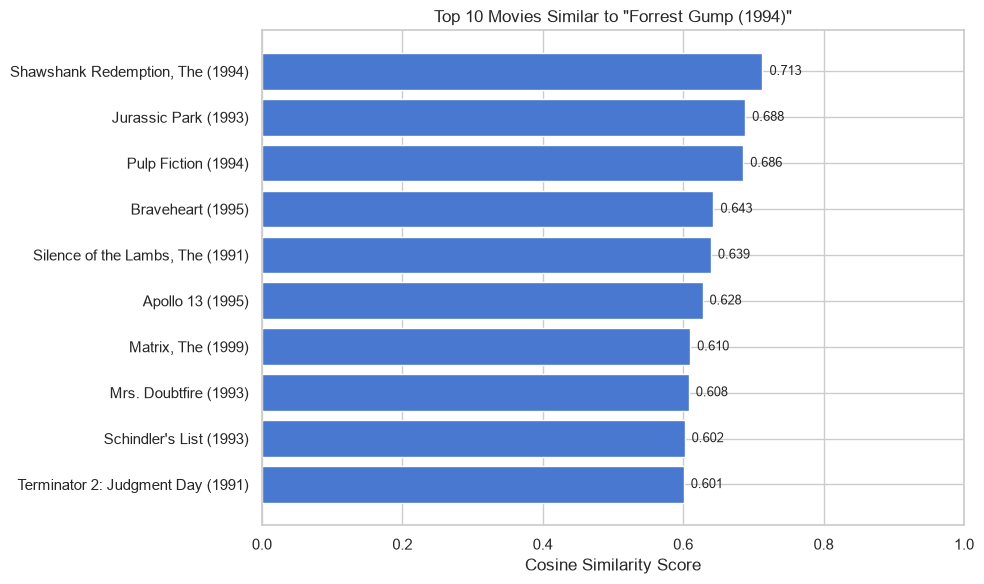

In [14]:
example_movie = 'Forrest Gump (1994)'
recs = get_recommendations(example_movie)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(recs['Movie'][::-1], recs['Similarity Score'][::-1])
ax.set_xlabel('Cosine Similarity Score')
ax.set_title(f'Top 10 Movies Similar to "{example_movie}"')
ax.set_xlim(0, 1)

for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.01, bar.get_y() + bar.get_height()/2,
            f'{width:.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

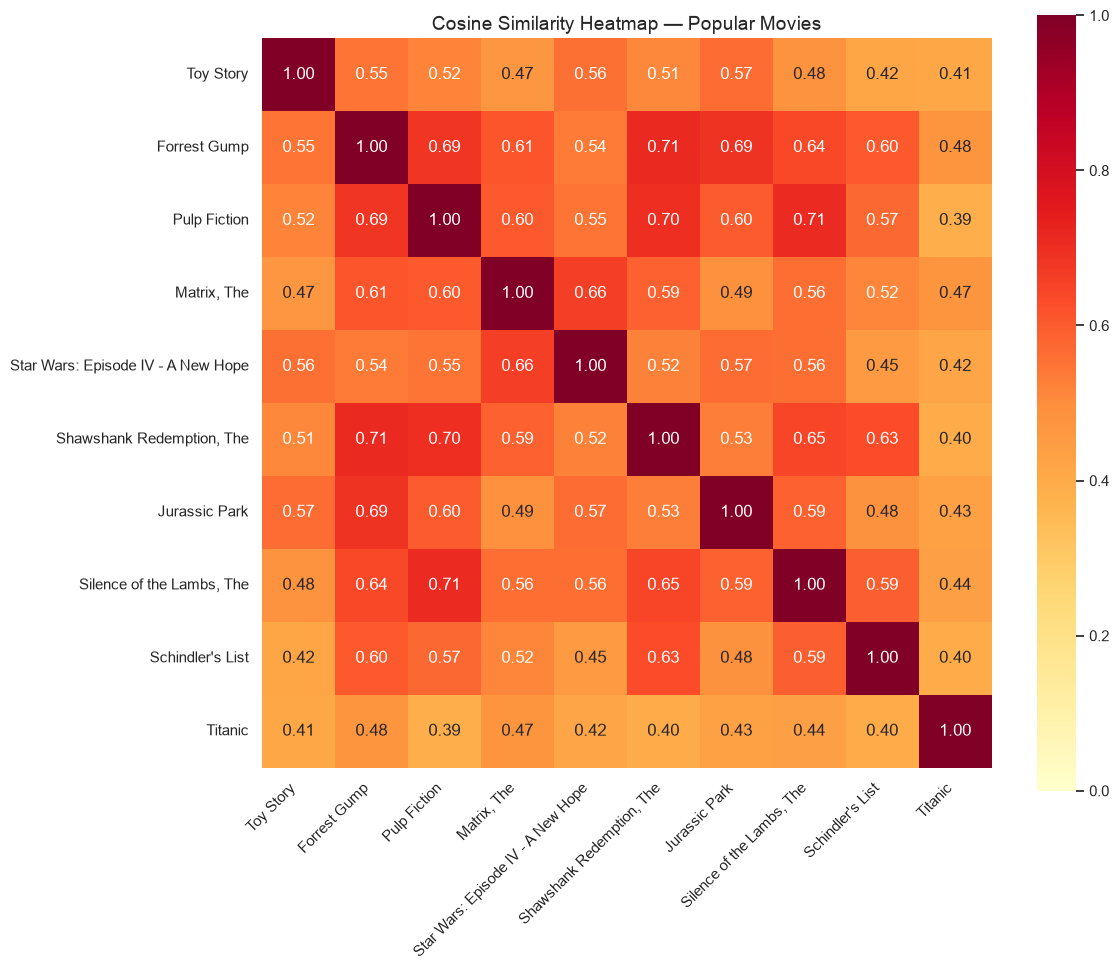

In [15]:
popular_titles = [
    'Toy Story (1995)',
    'Forrest Gump (1994)',
    'Pulp Fiction (1994)',
    'Matrix, The (1999)',
    'Star Wars: Episode IV - A New Hope (1977)',
    'Shawshank Redemption, The (1994)',
    'Jurassic Park (1993)',
    'Silence of the Lambs, The (1991)',
    'Schindler\'s List (1993)',
    'Titanic (1997)'
]

popular_in_data = [t for t in popular_titles if t in similarity_df.columns]
heatmap_data = similarity_df.loc[popular_in_data, popular_in_data]

fig, ax = plt.subplots(figsize=(12, 10))
short_labels = [t.split(' (')[0] for t in popular_in_data]

sns.heatmap(
    heatmap_data.values,
    xticklabels=short_labels,
    yticklabels=short_labels,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    vmin=0,
    vmax=1,
    square=True,
    ax=ax
)
ax.set_title('Cosine Similarity Heatmap — Popular Movies', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

---
## Conclusion

### Summary

This notebook implemented an **item-based collaborative filtering recommender system** using the MovieLens Small dataset. The system:

1. Builds a user-item rating matrix from 100,836 ratings across 610 users
2. Filters to movies with at least 10 ratings for reliable similarity estimates
3. Computes pairwise cosine similarity between all movie rating vectors
4. Recommends the 10 most similar movies given any movie title in the dataset

The recommendations produced are intuitive; for example, movies in similar genres and from similar eras tend to cluster together, and franchise entries (e.g., Star Wars films) score highly against each other.

### Limitations

- **Cold-Start Problem**: New movies with few or no ratings cannot be recommended, and new users with no rating history cannot receive personalized suggestions.
- **Sparsity**: The user-item matrix is ~98% empty. Most users have only rated a small fraction of available movies, which limits the reliability of similarity computations for less popular titles.
- **Scalability**: Computing a full pairwise similarity matrix becomes expensive as the number of movies grows. For production systems, approximate nearest neighbor methods or matrix factorization (e.g., SVD) would be more efficient.

### Possible Improvements

- **Matrix Factorization (SVD/NMF)**: Reduce dimensionality to capture latent factors and handle sparsity better.
- **Hybrid Approaches**: Combine collaborative filtering with content-based features (genres, tags) for more robust recommendations.
- **Implicit Feedback**: Incorporate viewing history or timestamps rather than relying solely on explicit ratings.